In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np

cwd = Path.cwd().resolve()
for project_root in (cwd, *cwd.parents):
    data_dir = project_root / 'data' / 'raw'
    if data_dir.is_dir():
        break
else:
    raise FileNotFoundError(f'No se encontro data/raw desde {cwd}. Ejecuta el notebook dentro del proyecto.')

df_orders = pd.read_csv(data_dir / 'orders.csv')
df_order_details = pd.read_csv(data_dir / 'order_details.csv')
df_products = pd.read_csv(data_dir / 'products.csv')
df_users = pd.read_csv(data_dir / 'users.csv')

In [4]:
df_orders.info()
display(df_orders.describe(include='all'))
display(df_orders.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124596 entries, 0 to 124595
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   order_id      124596 non-null  int64 
 1   user_id       124596 non-null  int64 
 2   status        124596 non-null  object
 3   gender        124596 non-null  object
 4   created_at    124596 non-null  object
 5   returned_at   12556 non-null   object
 6   shipped_at    80925 non-null   object
 7   delivered_at  43713 non-null   object
 8   num_of_item   124596 non-null  int64 
dtypes: int64(3), object(6)
memory usage: 8.6+ MB


,order_id,user_id,status,gender,created_at,returned_at,shipped_at,delivered_at,num_of_item
count,124596.000000,124596.000000,124596,124596,124596,12556,80925,43713,124596.000000
unique,NaN,NaN,5,2,118052,12511,79079,43175,NaN
top,NaN,NaN,Shipped,F,2025-02-09 07:07:00 UTC,2024-12-19 22:53:00 UTC,2025-02-09 04:25:00 UTC,2025-01-29 07:39:00 UTC,NaN
freq,NaN,NaN,37212,62393,5,3,3,3,NaN
mean,62298.500000,50067.964622,NaN,NaN,NaN,NaN,NaN,NaN,1.450047
std,35967.911407,28892.944246,NaN,NaN,NaN,NaN,NaN,NaN,0.803690
min,1.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
25%,31149.750000,25022.750000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
50%,62298.500000,50067.500000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
75%,93447.250000,75139.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000


,order_id,user_id,status,gender,created_at,returned_at,shipped_at,delivered_at,num_of_item
0,6,4,Cancelled,F,2022-03-23 12:47:00 UTC,NaN,NaN,NaN,4
1,9,7,Cancelled,F,2023-12-16 11:32:00 UTC,NaN,NaN,NaN,1
2,24,22,Cancelled,F,2022-11-19 10:06:00 UTC,NaN,NaN,NaN,2
3,26,24,Cancelled,F,2024-04-13 01:53:00 UTC,NaN,NaN,NaN,1
4,40,38,Cancelled,F,2024-09-03 12:05:00 UTC,NaN,NaN,NaN,1


In [5]:
df_order_details.info()
display(df_order_details.describe(include='all'))
display(df_order_details.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180670 entries, 0 to 180669
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 180670 non-null  int64  
 1   order_id           180670 non-null  int64  
 2   user_id            180670 non-null  int64  
 3   product_id         180670 non-null  int64  
 4   inventory_item_id  180670 non-null  int64  
 5   status             180670 non-null  object 
 6   created_at         180670 non-null  object 
 7   shipped_at         117250 non-null  object 
 8   delivered_at       63427 non-null   object 
 9   returned_at        18239 non-null   object 
 10  sale_price         180670 non-null  float64
dtypes: float64(1), int64(5), object(5)
memory usage: 15.2+ MB


,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
count,180670.000000,180670.000000,180670.000000,180670.000000,180670.000000,180670,180670,117250,63427,18239,180670.000000
unique,NaN,NaN,NaN,NaN,NaN,5,180499,79079,43175,12511,NaN
top,NaN,NaN,NaN,NaN,NaN,Shipped,2024-12-12 15:52:08 UTC,2023-03-29 23:05:00 UTC,2025-01-15 02:34:00 UTC,2024-12-30 16:00:00 UTC,NaN
freq,NaN,NaN,NaN,NaN,NaN,53823,2,8,8,6,NaN
mean,90335.500000,62152.056080,49950.240184,15264.929728,243872.033498,NaN,NaN,NaN,NaN,NaN,59.486039
std,52155.080905,35944.424826,28874.064572,8424.794926,140822.464938,NaN,NaN,NaN,NaN,NaN,66.242770
min,1.000000,1.000000,2.000000,1.000000,3.000000,NaN,NaN,NaN,NaN,NaN,0.020000
25%,45168.250000,31012.250000,24933.250000,7972.000000,122032.750000,NaN,NaN,NaN,NaN,NaN,24.639999
50%,90335.500000,62060.500000,49849.000000,15970.000000,243798.000000,NaN,NaN,NaN,NaN,NaN,39.990002
75%,135502.750000,93246.000000,74978.000000,22582.000000,365814.500000,NaN,NaN,NaN,NaN,NaN,69.949997


,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
0,42254,28981,23281,14235,114101,Complete,2024-05-19 14:37:21 UTC,2024-05-21 08:36:00 UTC,2024-05-25 04:22:00 UTC,NaN,0.02
1,176182,121497,97566,14235,475565,Complete,2024-03-28 05:47:52 UTC,2024-03-30 21:18:00 UTC,2024-04-03 06:05:00 UTC,NaN,0.02
2,56509,38842,31187,14235,152588,Returned,2024-03-26 15:37:10 UTC,2024-03-28 11:31:00 UTC,2024-03-30 12:25:00 UTC,2024-04-01 11:04:00 UTC,0.02
3,28210,19426,15633,14235,76077,Shipped,2023-08-13 09:31:49 UTC,2023-08-14 12:04:00 UTC,NaN,NaN,0.02
4,148743,102407,82349,14235,401633,Shipped,2024-03-04 08:27:02 UTC,2024-03-07 00:39:00 UTC,NaN,NaN,0.02


In [6]:
df_products.info()
display(df_products.describe(include='all'))
display(df_products.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29120 entries, 0 to 29119
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      29120 non-null  int64  
 1   cost                    29120 non-null  float64
 2   category                29120 non-null  object 
 3   name                    29118 non-null  object 
 4   brand                   29096 non-null  object 
 5   retail_price            29120 non-null  float64
 6   department              29120 non-null  object 
 7   sku                     29120 non-null  object 
 8   distribution_center_id  29120 non-null  int64  
dtypes: float64(2), int64(2), object(5)
memory usage: 2.0+ MB


,id,cost,category,name,brand,retail_price,department,sku,distribution_center_id
count,29120.000000,29120.000000,29120,29118,29096,29120.000000,29120,29120,29120.000000
unique,NaN,NaN,26,27309,2756,NaN,2,29120,NaN
top,NaN,NaN,Intimates,Wrangler Men's Premium Performance Cowboy Cut ...,Allegra K,NaN,Women,EBD58B8A3F1D72F4206201DA62FB1204,NaN
freq,NaN,NaN,2363,8,1034,NaN,15989,1,NaN
mean,14560.500000,28.481774,NaN,NaN,NaN,59.220164,NaN,NaN,4.982898
std,8406.364256,30.624681,NaN,NaN,NaN,65.888927,NaN,NaN,2.901153
min,1.000000,0.008300,NaN,NaN,NaN,0.020000,NaN,NaN,1.000000
25%,7280.750000,11.275613,NaN,NaN,NaN,24.000000,NaN,NaN,2.000000
50%,14560.500000,19.675081,NaN,NaN,NaN,39.990002,NaN,NaN,5.000000
75%,21840.250000,34.440000,NaN,NaN,NaN,69.949997,NaN,NaN,8.000000


,id,cost,category,name,brand,retail_price,department,sku,distribution_center_id
0,13842,2.51875,Accessories,Low Profile Dyed Cotton Twill Cap - Navy W39S55D,MG,6.25,Women,EBD58B8A3F1D72F4206201DA62FB1204,1
1,13928,2.33835,Accessories,Low Profile Dyed Cotton Twill Cap - Putty W39S55D,MG,5.95,Women,2EAC42424D12436BDD6A5B8A88480CC3,1
2,14115,4.87956,Accessories,Enzyme Regular Solid Army Caps-Black W35S45D,MG,10.99,Women,EE364229B2791D1EF9355708EFF0BA34,1
3,14157,4.64877,Accessories,Enzyme Regular Solid Army Caps-Olive W35S45D (...,MG,10.99,Women,00BD13095D06C20B11A2993CA419D16B,1
4,14273,6.50793,Accessories,Washed Canvas Ivy Cap - Black W11S64C,MG,15.99,Women,F531DC20FDE20B7ADF3A73F52B71D0AF,1


In [7]:
df_users.info()
display(df_users.describe(include='all'))
display(df_users.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              100000 non-null  int64  
 1   first_name      100000 non-null  object 
 2   last_name       100000 non-null  object 
 3   email           100000 non-null  object 
 4   age             100000 non-null  int64  
 5   gender          100000 non-null  object 
 6   state           100000 non-null  object 
 7   street_address  100000 non-null  object 
 8   postal_code     100000 non-null  object 
 9   city            99062 non-null   object 
 10  country         100000 non-null  object 
 11  latitude        100000 non-null  float64
 12  longitude       100000 non-null  float64
 13  traffic_source  100000 non-null  object 
 14  created_at      100000 non-null  object 
 15  user_geom       100000 non-null  object 
dtypes: float64(2), int64(2), object(12)
memory usage: 12.2+ M

,id,first_name,last_name,email,age,gender,state,street_address,postal_code,city,country,latitude,longitude,traffic_source,created_at,user_geom
count,100000.000000,100000,100000,100000,100000.00000,100000,100000,100000,100000,99062,100000,100000.000000,100000.000000,100000,100000,100000
unique,NaN,690,1000,83918,NaN,2,230,99998,15720,7897,15,NaN,NaN,5,98231,16411
top,NaN,Michael,Smith,michaelsmith@example.net,NaN,F,Guangdong,158 William Forges,02675-031,Shanghai,China,NaN,NaN,Search,2021-11-10 08:19:00 UTC,POINT(-46.74656621 -23.47256155)
freq,NaN,2258,2184,18,NaN,50254,5320,2,431,2528,33810,NaN,NaN,70133,3,431
mean,50000.500000,NaN,NaN,NaN,40.92700,NaN,NaN,NaN,NaN,NaN,NaN,28.341984,25.028849,NaN,NaN,NaN
std,28867.657797,NaN,NaN,NaN,17.01296,NaN,NaN,NaN,NaN,NaN,NaN,22.106049,89.856284,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,12.00000,NaN,NaN,NaN,NaN,NaN,NaN,-43.007536,-158.164931,NaN,NaN,NaN
25%,25000.750000,NaN,NaN,NaN,26.00000,NaN,NaN,NaN,NaN,NaN,NaN,26.094341,-50.452775,NaN,NaN,NaN
50%,50000.500000,NaN,NaN,NaN,41.00000,NaN,NaN,NaN,NaN,NaN,NaN,35.275626,4.701404,NaN,NaN,NaN
75%,75000.250000,NaN,NaN,NaN,56.00000,NaN,NaN,NaN,NaN,NaN,NaN,40.739088,116.385652,NaN,NaN,NaN


,id,first_name,last_name,email,age,gender,state,street_address,postal_code,city,country,latitude,longitude,traffic_source,created_at,user_geom
0,13190,Justin,Gilbert,justingilbert@example.org,65,M,Acre,504 Corey Island,69980-000,NaN,Brasil,-8.065346,-72.870949,Organic,2022-03-03 00:09:00 UTC,POINT(-72.87094866 -8.065346116)
1,32111,Linda,Beltran,lindabeltran@example.com,51,F,Acre,1996 Daugherty Walk,69980-000,NaN,Brasil,-8.065346,-72.870949,Email,2022-11-17 16:14:00 UTC,POINT(-72.87094866 -8.065346116)
2,98036,Jesse,Carlson,jessecarlson@example.com,27,M,Acre,1952 Turner Circle Apt. 921,69980-000,NaN,Brasil,-8.065346,-72.870949,Search,2019-10-08 08:19:00 UTC,POINT(-72.87094866 -8.065346116)
3,71960,Brenda,Bowman,brendabowman@example.net,69,F,Acre,0954 Marshall Parkway Apt. 530,69980-000,NaN,Brasil,-8.065346,-72.870949,Facebook,2021-06-18 01:34:00 UTC,POINT(-72.87094866 -8.065346116)
4,87286,Kathryn,Norton,kathrynnorton@example.org,57,F,Acre,2872 Jones View Suite 439,69980-000,NaN,Brasil,-8.065346,-72.870949,Search,2024-04-10 18:50:00 UTC,POINT(-72.87094866 -8.065346116)


In [8]:
def get_range_date(df, column, table_name):
    df[column] = pd.to_datetime(df[column], format='mixed', utc=True)
    print(f"{table_name}")
    print(f"Fecha mínima en {df[column].min()} \nFecha máxima en {df[column].max()}")
    print("*" * 80)

get_range_date(df_orders, 'created_at', 'orders')
get_range_date(df_order_details, 'created_at', 'order_details')
get_range_date(df_users, 'created_at', 'users')

print(f"Total de usuarios únicos: {df_users['id'].nunique()}")
print(f"Total de órdenes: {df_orders['order_id'].nunique()}")
print(f"Total de usuarios con órdenes: {df_orders['user_id'].nunique()}")
print(f"Total de detalles de orden: {len(df_order_details)}")

orders
Fecha mínima en 2019-01-22 14:50:00+00:00 
Fecha máxima en 2025-02-14 19:31:25.006404+00:00
********************************************************************************
order_details
Fecha mínima en 2019-01-22 12:21:36+00:00 
Fecha máxima en 2025-02-18 18:26:43.894638+00:00
********************************************************************************
users
Fecha mínima en 2019-01-02 00:28:00+00:00 
Fecha máxima en 2025-02-13 19:31:25.006404+00:00
********************************************************************************
Total de usuarios únicos: 100000
Total de órdenes: 124596
Total de usuarios con órdenes: 80012
Total de detalles de orden: 180670


In [9]:
print(df_order_details['status'].unique())
completed_orders = df_order_details[df_order_details['status'] == 'Complete'].copy()

first_purchase = completed_orders.groupby('user_id')['created_at'].min().reset_index()
first_purchase.columns = ['user_id', 'first_purchase_date']
display(first_purchase.head(10))
print(f"Usuarios con al menos una compra completada: {len(first_purchase)}")

['Complete' 'Returned' 'Shipped' 'Cancelled' 'Processing']


,user_id,first_purchase_date
0,3,2024-06-04 00:55:58+00:00
1,5,2024-11-20 16:33:39+00:00
2,14,2024-06-02 00:43:18+00:00
3,16,2022-05-12 10:48:24+00:00
4,18,2023-07-09 07:51:24+00:00
5,22,2025-01-19 06:32:26+00:00
6,23,2023-09-12 06:37:39+00:00
7,27,2023-10-11 22:54:04+00:00
8,28,2024-02-02 13:22:40+00:00
9,35,2024-12-17 23:50:10+00:00


Usuarios con al menos una compra completada: 27627


In [10]:
repurchase_data = []

for _, row in first_purchase.iterrows():
    user_id = row['user_id']
    first_date = row['first_purchase_date']
    
    user_orders = completed_orders[
        (completed_orders['user_id'] == user_id) & 
        (completed_orders['created_at'] > first_date)
    ]
    
    if len(user_orders) > 0:
        second_purchase_date = user_orders['created_at'].min()
        days_to_repurchase = (second_purchase_date - first_date).days
        
        repurchased_60d = 1 if days_to_repurchase <= 60 else 0
    else:
        days_to_repurchase = None
        repurchased_60d = 0
    
    repurchase_data.append({
        'user_id': user_id,
        'first_purchase_date': first_date,
        'days_to_repurchase': days_to_repurchase,
        'repurchased_60d': repurchased_60d
    })

target_df = pd.DataFrame(repurchase_data)

print("Distribución de la variable objetivo:")
print(target_df['repurchased_60d'].value_counts())
print(f"Tasa de recompra en 60 días: {target_df['repurchased_60d'].mean():.3f}")

print(f"Usuarios que hicieron recompra: {target_df['repurchased_60d'].sum()}")
print(f"Usuarios que NO hicieron recompra en 60 días: {(target_df['repurchased_60d'] == 0).sum()}")

repurchasers = target_df[target_df['days_to_repurchase'].notna()]
print(f"Promedio de días hasta recompra (para quienes recompraron): {repurchasers['days_to_repurchase'].mean():.1f}")
print(f"Mediana de días hasta recompra: {repurchasers['days_to_repurchase'].median():.1f}")

Distribución de la variable objetivo:
repurchased_60d
0    18767
1     8860
Name: count, dtype: int64
Tasa de recompra en 60 días: 0.321
Usuarios que hicieron recompra: 8860
Usuarios que NO hicieron recompra en 60 días: 18767
Promedio de días hasta recompra (para quienes recompraron): 76.6
Mediana de días hasta recompra: 1.0


## Feature engineering

In [11]:
user_features = df_users[['id', 'age', 'gender', 'state', 'country', 'traffic_source']].copy()
user_features = user_features.rename(columns={'id': 'user_id'})

In [12]:
first_purchase

,user_id,first_purchase_date
0,3,2024-06-04 00:55:58+00:00
1,5,2024-11-20 16:33:39+00:00
2,14,2024-06-02 00:43:18+00:00
3,16,2022-05-12 10:48:24+00:00
4,18,2023-07-09 07:51:24+00:00
...,...,...
27622,99981,2023-09-11 09:43:43+00:00
27623,99989,2023-09-12 23:26:06+00:00
27624,99992,2024-09-30 08:37:16+00:00
27625,99995,2024-10-08 10:15:05+00:00


In [13]:
first_purchase_details = []

for _, row in first_purchase.iterrows():
    user_id = row['user_id']
    first_date = row['first_purchase_date']
    
    first_order_details = completed_orders[
        (completed_orders['user_id'] == user_id) & 
        (completed_orders['created_at'] == first_date)
    ]
    
    if len(first_order_details) > 0:
        product_ids = first_order_details['product_id'].tolist()
        product_info = df_products[df_products['id'].isin(product_ids)]
        
        feature_dict = {
            'user_id': user_id,
            'first_purchase_date': first_date,
            'first_order_items': len(first_order_details),
            'first_order_total_value': first_order_details['sale_price'].sum(),
            'first_order_avg_price': first_order_details['sale_price'].mean(),
            'first_order_max_price': first_order_details['sale_price'].max(),
            'first_order_min_price': first_order_details['sale_price'].min(),
        }
        
        if len(product_info) > 0:
            feature_dict.update({
                'first_order_avg_cost': product_info['cost'].mean(),
                'first_order_avg_retail_price': product_info['retail_price'].mean(),
                'first_order_categories': product_info['category'].nunique(),
                'first_order_brands': product_info['brand'].nunique(),
                'first_order_departments': product_info['department'].nunique(),
                'most_common_category': product_info['category'].mode().iloc[0] if len(product_info['category'].mode()) > 0 else 'Unknown',
                'most_common_brand': product_info['brand'].mode().iloc[0] if len(product_info['brand'].mode()) > 0 else 'Unknown',
                'most_common_department': product_info['department'].mode().iloc[0] if len(product_info['department'].mode()) > 0 else 'Unknown'
            })
        else:
            feature_dict.update({
                'first_order_avg_cost': 0,
                'first_order_avg_retail_price': 0,
                'first_order_categories': 0,
                'first_order_brands': 0,
                'first_order_departments': 0,
                'most_common_category': 'Unknown',
                'most_common_brand': 'Unknown',
                'most_common_department': 'Unknown'
            })
        
        first_purchase_details.append(feature_dict)

In [14]:
first_purchase_features = pd.DataFrame(first_purchase_details)
print(f"Features de primera compra creadas para {len(first_purchase_features)} usuarios")
first_purchase_features

Features de primera compra creadas para 27627 usuarios


,user_id,first_purchase_date,first_order_items,first_order_total_value,first_order_avg_price,first_order_max_price,first_order_min_price,first_order_avg_cost,first_order_avg_retail_price,first_order_categories,first_order_brands,first_order_departments,most_common_category,most_common_brand,most_common_department
0,3,2024-06-04 00:55:58+00:00,1,32.169998,32.169998,32.169998,32.169998,14.766029,32.169998,1,1,1,Fashion Hoodies & Sweatshirts,Weatherproof,Women
1,5,2024-11-20 16:33:39+00:00,1,25.000000,25.000000,25.000000,25.000000,14.400000,25.000000,1,1,1,Socks,Gold Toe,Men
2,14,2024-06-02 00:43:18+00:00,1,10.980000,10.980000,10.980000,10.980000,6.082920,10.980000,1,1,1,Intimates,Ilusion,Women
3,16,2022-05-12 10:48:24+00:00,1,37.740002,37.740002,37.740002,37.740002,18.077461,37.740002,1,1,1,Sweaters,Nautica,Men
4,18,2023-07-09 07:51:24+00:00,1,36.279999,36.279999,36.279999,36.279999,18.357679,36.279999,1,1,1,Shorts,PAIGE,Women
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27622,99981,2023-09-11 09:43:43+00:00,1,42.049999,42.049999,42.049999,42.049999,18.502000,42.049999,1,1,1,Active,Champion,Men
27623,99989,2023-09-12 23:26:06+00:00,1,69.500000,69.500000,69.500000,69.500000,26.271000,69.500000,1,1,1,Suits & Sport Coats,Billabong,Men
27624,99992,2024-09-30 08:37:16+00:00,1,25.500000,25.500000,25.500000,25.500000,11.194500,25.500000,1,1,1,Sleep & Lounge,DFDesigns,Men
27625,99995,2024-10-08 10:15:05+00:00,1,19.980000,19.980000,19.980000,19.980000,8.531460,19.980000,1,1,1,Maternity,Motherhood Maternity,Women


In [15]:
# features temporales
first_purchase_features['first_purchase_hour'] = first_purchase_features['first_purchase_date'].dt.hour
first_purchase_features['first_purchase_day_of_week'] = first_purchase_features['first_purchase_date'].dt.dayofweek
first_purchase_features['first_purchase_month'] = first_purchase_features['first_purchase_date'].dt.month
first_purchase_features['first_purchase_year'] = first_purchase_features['first_purchase_date'].dt.year

user_registration = df_users[['id', 'created_at']].copy()
user_registration = user_registration.rename(columns={'id': 'user_id', 'created_at': 'registration_date'})

first_purchase_features = first_purchase_features.merge(user_registration, on='user_id', how='left')
first_purchase_features['days_registration_to_first_purchase'] = (
    first_purchase_features['first_purchase_date'] - first_purchase_features['registration_date']
).dt.days

first_purchase_features

,user_id,first_purchase_date,first_order_items,first_order_total_value,first_order_avg_price,first_order_max_price,first_order_min_price,first_order_avg_cost,first_order_avg_retail_price,first_order_categories,...,first_order_departments,most_common_category,most_common_brand,most_common_department,first_purchase_hour,first_purchase_day_of_week,first_purchase_month,first_purchase_year,registration_date,days_registration_to_first_purchase
0,3,2024-06-04 00:55:58+00:00,1,32.169998,32.169998,32.169998,32.169998,14.766029,32.169998,1,...,1,Fashion Hoodies & Sweatshirts,Weatherproof,Women,0,1,6,2024,2022-05-13 03:26:00+00:00,752
1,5,2024-11-20 16:33:39+00:00,1,25.000000,25.000000,25.000000,25.000000,14.400000,25.000000,1,...,1,Socks,Gold Toe,Men,16,2,11,2024,2024-11-09 17:27:00+00:00,10
2,14,2024-06-02 00:43:18+00:00,1,10.980000,10.980000,10.980000,10.980000,6.082920,10.980000,1,...,1,Intimates,Ilusion,Women,0,6,6,2024,2024-04-22 04:23:00+00:00,40
3,16,2022-05-12 10:48:24+00:00,1,37.740002,37.740002,37.740002,37.740002,18.077461,37.740002,1,...,1,Sweaters,Nautica,Men,10,3,5,2022,2020-10-16 13:14:00+00:00,572
4,18,2023-07-09 07:51:24+00:00,1,36.279999,36.279999,36.279999,36.279999,18.357679,36.279999,1,...,1,Shorts,PAIGE,Women,7,6,7,2023,2020-05-10 09:23:00+00:00,1154
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27622,99981,2023-09-11 09:43:43+00:00,1,42.049999,42.049999,42.049999,42.049999,18.502000,42.049999,1,...,1,Active,Champion,Men,9,0,9,2023,2022-06-16 10:13:00+00:00,451
27623,99989,2023-09-12 23:26:06+00:00,1,69.500000,69.500000,69.500000,69.500000,26.271000,69.500000,1,...,1,Suits & Sport Coats,Billabong,Men,23,1,9,2023,2019-11-04 02:05:00+00:00,1408
27624,99992,2024-09-30 08:37:16+00:00,1,25.500000,25.500000,25.500000,25.500000,11.194500,25.500000,1,...,1,Sleep & Lounge,DFDesigns,Men,8,0,9,2024,2024-09-16 08:41:00+00:00,13
27625,99995,2024-10-08 10:15:05+00:00,1,19.980000,19.980000,19.980000,19.980000,8.531460,19.980000,1,...,1,Maternity,Motherhood Maternity,Women,10,1,10,2024,2024-05-13 13:18:00+00:00,147


In [16]:
# join features
final_features = target_df.merge(first_purchase_features, on='user_id', how='left')
final_features = final_features.merge(user_features, on='user_id', how='left')
final_features

,user_id,first_purchase_date_x,days_to_repurchase,repurchased_60d,first_purchase_date_y,first_order_items,first_order_total_value,first_order_avg_price,first_order_max_price,first_order_min_price,...,first_purchase_day_of_week,first_purchase_month,first_purchase_year,registration_date,days_registration_to_first_purchase,age,gender,state,country,traffic_source
0,3,2024-06-04 00:55:58+00:00,NaN,0,2024-06-04 00:55:58+00:00,1,32.169998,32.169998,32.169998,32.169998,...,1,6,2024,2022-05-13 03:26:00+00:00,752,56,F,Pays de la Loire,France,Organic
1,5,2024-11-20 16:33:39+00:00,NaN,0,2024-11-20 16:33:39+00:00,1,25.000000,25.000000,25.000000,25.000000,...,2,11,2024,2024-11-09 17:27:00+00:00,10,44,M,Tokyo,Japan,Email
2,14,2024-06-02 00:43:18+00:00,NaN,0,2024-06-02 00:43:18+00:00,1,10.980000,10.980000,10.980000,10.980000,...,6,6,2024,2024-04-22 04:23:00+00:00,40,26,F,Beijing,China,Search
3,16,2022-05-12 10:48:24+00:00,NaN,0,2022-05-12 10:48:24+00:00,1,37.740002,37.740002,37.740002,37.740002,...,3,5,2022,2020-10-16 13:14:00+00:00,572,37,M,Pays de la Loire,France,Search
4,18,2023-07-09 07:51:24+00:00,NaN,0,2023-07-09 07:51:24+00:00,1,36.279999,36.279999,36.279999,36.279999,...,6,7,2023,2020-05-10 09:23:00+00:00,1154,65,F,Oregon,United States,Search
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27622,99981,2023-09-11 09:43:43+00:00,NaN,0,2023-09-11 09:43:43+00:00,1,42.049999,42.049999,42.049999,42.049999,...,0,9,2023,2022-06-16 10:13:00+00:00,451,50,M,Arizona,United States,Search
27623,99989,2023-09-12 23:26:06+00:00,NaN,0,2023-09-12 23:26:06+00:00,1,69.500000,69.500000,69.500000,69.500000,...,1,9,2023,2019-11-04 02:05:00+00:00,1408,32,M,Arizona,United States,Search
27624,99992,2024-09-30 08:37:16+00:00,NaN,0,2024-09-30 08:37:16+00:00,1,25.500000,25.500000,25.500000,25.500000,...,0,9,2024,2024-09-16 08:41:00+00:00,13,36,M,Goiás,Brasil,Search
27625,99995,2024-10-08 10:15:05+00:00,NaN,0,2024-10-08 10:15:05+00:00,1,19.980000,19.980000,19.980000,19.980000,...,1,10,2024,2024-05-13 13:18:00+00:00,147,67,F,Gyeonggi-do,South Korea,Search


## Preprocessing

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
modelling_df = final_features.copy()

columns_to_drop = [
    'user_id',
    'first_purchase_date_x',
    'first_purchase_date_y', 
    'days_to_repurchase',
    'registration_date'
]
modelling_df = modelling_df.drop(columns=columns_to_drop)
modelling_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27627 entries, 0 to 27626
Data columns (total 24 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   repurchased_60d                      27627 non-null  int64  
 1   first_order_items                    27627 non-null  int64  
 2   first_order_total_value              27627 non-null  float64
 3   first_order_avg_price                27627 non-null  float64
 4   first_order_max_price                27627 non-null  float64
 5   first_order_min_price                27627 non-null  float64
 6   first_order_avg_cost                 27627 non-null  float64
 7   first_order_avg_retail_price         27627 non-null  float64
 8   first_order_categories               27627 non-null  int64  
 9   first_order_brands                   27627 non-null  int64  
 10  first_order_departments              27627 non-null  int64  
 11  most_common_category        

### Split dataset

In [95]:
X = modelling_df.drop('repurchased_60d', axis=1)
y = modelling_df['repurchased_60d']

train_test_split_args = {
    'test_size': 0.2,
    'random_state': 42,
}

stratify = True
if stratify:
    train_test_split_args['stratify'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, **train_test_split_args
)

print(f"Train: {X_train.shape[0]} muestras")
print(f"Test: {X_test.shape[0]} muestras")
print(f"Tasa de clase positiva: {y.mean():.3f}")
print(f"Tasa de clase positiva en train: {y_train.mean():.3f}")
print(f"Tasa de clase positiva en test: {y_test.mean():.3f}")

Train: 22101 muestras
Test: 5526 muestras
Tasa de clase positiva: 0.321
Tasa de clase positiva en train: 0.321
Tasa de clase positiva en test: 0.321


In [20]:
categorical_features = X.select_dtypes(include="object").columns.tolist()
numerical_features   = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

In [21]:
for col in categorical_features:
    print(f'{col}: {X[col].nunique()}')

most_common_category: 26
most_common_brand: 2310
most_common_department: 2
gender: 2
state: 220
country: 14
traffic_source: 5


### Pipeline for XGB & RF

In [22]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, numerical_features),
    ("cat", cat_pipe, categorical_features)
])

### Pipeline for LR

In [23]:
XLR_train = X_train.copy()
for col in categorical_features:
    if XLR_train[col].nunique() > 5:
        XLR_train = XLR_train.drop(columns=[col])

categorical_features_lr = XLR_train.select_dtypes(include="object").columns.tolist()

for col in categorical_features_lr:
    print(f'{col}: {XLR_train[col].nunique()}')

XLR_test = X_test[XLR_train.columns]

most_common_department: 2
gender: 2
traffic_source: 5


In [24]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_lr = ColumnTransformer([
    ("num", num_pipe, numerical_features),
    ("cat", cat_pipe, categorical_features_lr)
])

## Training

In [110]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_results = {}

### XGBoost

In [111]:
import xgboost as xgb


hyperparameters_xgb = {
    'n_estimators': 200,
    'max_depth': 8,
    'learning_rate': 0.05,
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'random_state': 42,
    'eval_metric': 'auc'
}

clf_xgb = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "model",
            xgb.XGBClassifier(
                **hyperparameters_xgb
            ),
        ),
    ]
)

clf_xgb.fit(X_train, y_train)
print("Score test:", clf_xgb.score(X_test, y_test))
y_pred_xgb = clf_xgb.predict(X_test)
y_proba_xgb = clf_xgb.predict_proba(X_test)[:, 1]


metrics_xgb = {
    "accuracy": accuracy_score(y_test, y_pred_xgb),
    "precision": precision_score(y_test, y_pred_xgb),
    "recall": recall_score(y_test, y_pred_xgb),
    "f1": f1_score(y_test, y_pred_xgb),
    "auc": roc_auc_score(y_test, y_proba_xgb),
}

model_results["xgboost"] = metrics_xgb

Score test: 0.670647846543612


### RF

In [112]:
hyperparameters_rf = {
    'n_estimators': 10,
    'max_depth': 20,
    'min_samples_split': 10,
    'min_samples_leaf': 1,
    'random_state': 42,
    'n_jobs': -1,
}

clf_rf = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                **hyperparameters_rf
            ),
        ),
    ]
)

clf_rf.fit(X_train, y_train)
print("Score test:", clf_rf.score(X_test, y_test))
y_pred_rf = clf_rf.predict(X_test)
y_proba_rf = clf_rf.predict_proba(X_test)[:, 1]


metrics_rf = {
    "accuracy": accuracy_score(y_test, y_pred_rf),
    "precision": precision_score(y_test, y_pred_rf),
    "recall": recall_score(y_test, y_pred_rf),
    "f1": f1_score(y_test, y_pred_rf),
    "auc": roc_auc_score(y_test, y_proba_rf),
}

model_results["randomforest"] = metrics_rf

Score test: 0.6601520086862106


### LR

In [113]:
hyperparameters_lr = {
    'max_iter': 1000,
    'class_weight': 'balanced',
    'random_state': 42
}


clf_lr = Pipeline(
    [
        ("preprocessor", preprocessor_lr),
        (
            "model",
            LogisticRegression(
                **hyperparameters_lr
                ),
        ),
    ]
)

clf_lr.fit(XLR_train, y_train)
print("Score test:", clf_lr.score(XLR_test, y_test))
y_pred_lr = clf_lr.predict(XLR_test)
y_proba_lr = clf_lr.predict_proba(XLR_test)[:, 1]


metrics_lr = {
    "accuracy": accuracy_score(y_test, y_pred_lr),
    "precision": precision_score(y_test, y_pred_lr),
    "recall": recall_score(y_test, y_pred_lr),
    "f1": f1_score(y_test, y_pred_lr),
    "auc": roc_auc_score(y_test, y_proba_lr),
}

model_results["logisticregression"] = metrics_lr

Score test: 0.47213174086138254


In [114]:
import joblib

joblib.dump(clf_xgb, './xgboost_model.pkl')
joblib.dump(clf_rf, './randomforest_model.pkl')
joblib.dump(clf_lr, './logisticregression_model.pkl')

['./logisticregression_model.pkl']

## Evaluation

In [115]:
comparison_df = pd.DataFrame(model_results).T
print(comparison_df.round(4))

best_model_name = comparison_df['auc'].idxmax()

if best_model_name == 'randomforest':
    best_model = clf_rf
    best_pred_proba = y_proba_rf
elif best_model_name == 'logisticregression':
    best_model = clf_lr
    best_pred_proba = y_proba_lr
elif best_model_name == 'xgboost':   
    best_model = clf_xgb
    best_pred_proba = y_proba_xgb

print(f"Modelo seleccionado por mayor AUC: {best_model_name}")

                    accuracy  precision  recall      f1     auc
xgboost               0.6706     0.3333  0.0271  0.0501  0.5079
randomforest          0.6602     0.3441  0.0660  0.1108  0.5028
logisticregression    0.4721     0.3217  0.5830  0.4146  0.5064
Modelo seleccionado por mayor AUC: xgboost


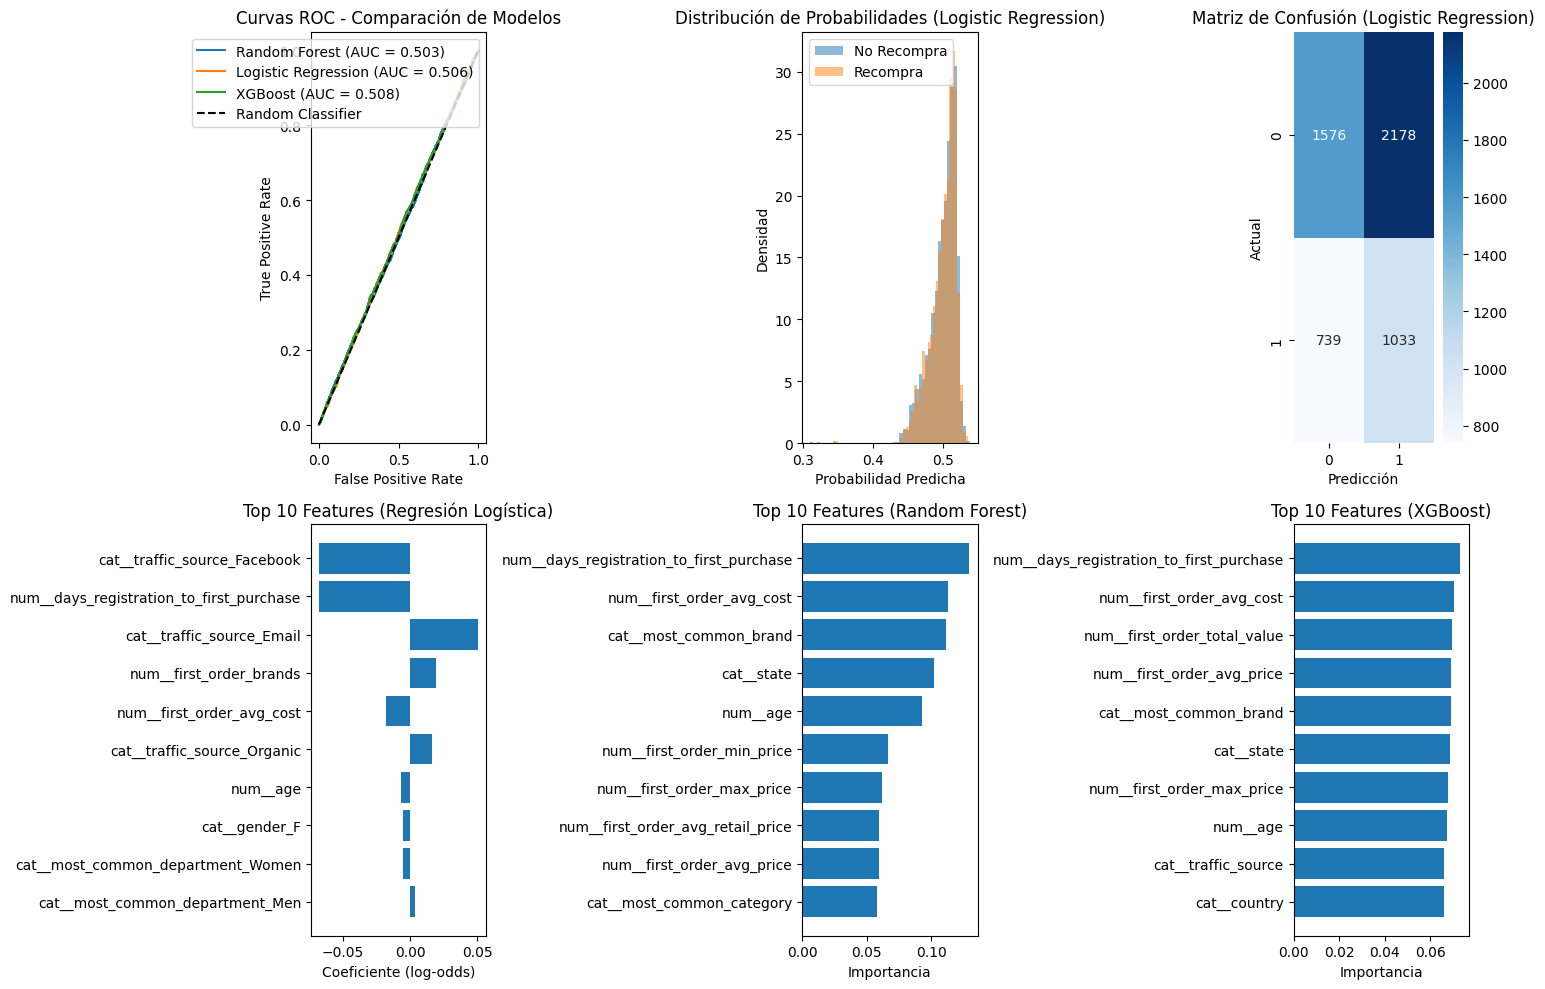

In [116]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)

plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {metrics_rf["auc"]:.3f})')
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {metrics_lr["auc"]:.3f})')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {metrics_xgb["auc"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curvas ROC - Comparación de Modelos')
plt.legend()

plt.subplot(2, 3, 2)
plt.hist(y_proba_lr[y_test == 0], alpha=0.5, label='No Recompra', bins=50, density=True)
plt.hist(y_proba_lr[y_test == 1], alpha=0.5, label='Recompra', bins=50, density=True)
plt.xlabel('Probabilidad Predicha')
plt.ylabel('Densidad')
plt.title('Distribución de Probabilidades (Logistic Regression)')
plt.legend()

plt.subplot(2, 3, 3)
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión (Logistic Regression)')
plt.ylabel('Actual')
plt.xlabel('Predicción')

plt.subplot(2, 3, 4)
coefs = clf_lr.named_steps["model"].coef_[0]
feature_names = clf_lr.named_steps["preprocessor"].get_feature_names_out()
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coef": coefs,
    "abs_coef": abs(coefs)
}).sort_values("abs_coef", ascending=False)

top_features = coef_df.head(10)
plt.barh(top_features["feature"], top_features["coef"])
plt.xlabel("Coeficiente (log-odds)")
plt.title("Top 10 Features (Regresión Logística)")
plt.gca().invert_yaxis()

plt.subplot(2, 3, 5)
feature_names = clf_rf.named_steps["preprocessor"].get_feature_names_out()
importances = clf_rf.named_steps["model"].feature_importances_
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

top_features = feature_importance.head(10)
plt.barh(range(len(top_features)), top_features['importance'])
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Importancia')
plt.title('Top 10 Features (Random Forest)')
plt.gca().invert_yaxis()

plt.subplot(2, 3, 6)
feature_names = clf_xgb.named_steps["preprocessor"].get_feature_names_out()
importances = clf_xgb.named_steps["model"].feature_importances_
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

top_features = feature_importance.head(10)
plt.barh(range(len(top_features)), top_features['importance'])
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Importancia')
plt.title('Top 10 Features (XGBoost)')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [117]:
onehot = clf_lr.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
feature_names = onehot.get_feature_names_out(categorical_features_lr)

# Por género
gender_analysis = modelling_df.groupby("gender")["repurchased_60d"].agg(["count", "mean"]).round(3)
print("\nTasa de recompra por género:")
for gender, row in gender_analysis.iterrows():
    print(f"  {gender}: {row['mean']:.3f} ({row['count']} usuarios)")


# Por fuente de tráfico
traffic_analysis = modelling_df.groupby("traffic_source")["repurchased_60d"].agg(["count", "mean"]).round(3)
print("\nTasa de recompra por fuente de tráfico:")
for traffic_source, row in traffic_analysis.iterrows():
    print(f"  {traffic_source}: {row['mean']:.3f} ({row['count']} usuarios)")


# Por valor de primera compra
modelling_df['value_segment'] = pd.cut(modelling_df['first_order_total_value'], 
                                     bins=[0, 20, 50, 100, float('inf')], 
                                     labels=['Bajo (≤$20)', 'Medio ($20-50)', 'Alto ($50-100)', 'Premium (>$100)'])

value_analysis = modelling_df.groupby('value_segment', observed=True)['repurchased_60d'].agg(['count', 'mean']).round(3)
print("\nTasa de recompra por segmento de valor:")
for segment, row in value_analysis.iterrows():
    print(f"  {segment}: {row['mean']:.3f} ({row['count']} usuarios)")

# Por tiempo entre registro y primera compra
modelling_df['time_to_purchase_segment'] = pd.cut(modelling_df['days_registration_to_first_purchase'], 
                                                bins=[0, 30, 90, 365, float('inf')], 
                                                labels=['Inmediato (≤30d)', 'Rápido (30-90d)', 'Medio (90-365d)', 'Lento (>365d)'])

time_analysis = modelling_df.groupby('time_to_purchase_segment', observed=True)['repurchased_60d'].agg(['count', 'mean']).round(3)
print("\nTasa de recompra por tiempo hasta primera compra:")
for segment, row in time_analysis.iterrows():
    print(f"  {segment}: {row['mean']:.3f} ({row['count']} usuarios)")



Tasa de recompra por género:
  F: 0.320 (13879.0 usuarios)
  M: 0.321 (13748.0 usuarios)

Tasa de recompra por fuente de tráfico:
  Display: 0.321 (1141.0 usuarios)
  Email: 0.331 (1334.0 usuarios)
  Facebook: 0.307 (1634.0 usuarios)
  Organic: 0.324 (4077.0 usuarios)
  Search: 0.320 (19441.0 usuarios)

Tasa de recompra por segmento de valor:
  Bajo (≤$20): 0.327 (5729.0 usuarios)
  Medio ($20-50): 0.316 (11517.0 usuarios)
  Alto ($50-100): 0.326 (6495.0 usuarios)
  Premium (>$100): 0.318 (3886.0 usuarios)

Tasa de recompra por tiempo hasta primera compra:
  Inmediato (≤30d): 0.387 (2295.0 usuarios)
  Rápido (30-90d): 0.320 (2775.0 usuarios)
  Medio (90-365d): 0.322 (8116.0 usuarios)
  Lento (>365d): 0.310 (13979.0 usuarios)
